# **Case Study: Predicting Apartment Prices from Layout and Location**

This notebook recreates the apartment-price case study with the current `utils` API. It covers EDA, geographical feature analysis, cleaning, splitting, outlier handling, encoding, feature selection, scaling, baseline regressors, tuning, interpretability, final test evaluation, and artifact saving.

**Target:** `TotalCost` (apartment price).

**Business context:** A developer wants a repeatable valuation baseline for new apartment listings. The model supports pricing discussions and helps identify listings that deserve manual review.

## **STAGE 0: BUSINESS UNDERSTANDING**

### Problem statement
Apartment prices depend on size, layout, finishing, building class, floor, and location. The sales team currently prices units using experience and a few rules of thumb. A data-driven baseline can make pricing more consistent and expose which features drive value.

### Goals
- Understand the main price drivers.
- Quantify the value of location (`District`) without leaking target information.
- Build a leakage-safe regression pipeline.
- Compare linear and tree-based models.
- Tune the strongest candidate and evaluate it on a held-out test set.
- Save the model and preprocessing artifacts for inference.

### Success criteria
- Test R² meaningfully above zero.
- MAE and RMSE reported in the target currency.
- Preprocessing fitted on training data only.
- Reproducible artifacts for inference.

## **STAGE 1: PROJECT SETUP**

In [1]:
from pathlib import Path
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

from utils import (
    calculate_correlation_tabular,
    calculate_feature_importance,
    check_data_information,
    compare_cv_metrics_regression,
    describe_categorical_combined,
    describe_numerical_combined,
    eval_regression,
    feature_encoding,
    feature_scaling,
    filter_outliers,
    get_model_pipeline,
    handle_missing_values,
    plot_correlation_heatmap,
    plot_dynamic_countplot,
    plot_dynamic_hisplots_kdeplots,
    tune_single_model_regression,
)

warnings.filterwarnings("ignore")
sns.set_style("darkgrid")
pd.set_option("display.max_columns", None)

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
DATA_PATH = PROJECT_ROOT / "data" / "regression_data_2.csv"
ARTIFACT_DIR = PROJECT_ROOT / "models" / "new_regression_2"
print(f"Project root: {PROJECT_ROOT}")
print(f"Data path:    {DATA_PATH}")
print(f"Artifacts:    {ARTIFACT_DIR}")

Project root: e:\Data Science Utils
Data path:    e:\Data Science Utils\data\regression_data_2.csv
Artifacts:    e:\Data Science Utils\models\new_regression_2


## **STAGE 2: LOAD AND INSPECT THE DATA**

In [2]:
df_raw = pd.read_csv(DATA_PATH, low_memory=False)
df = df_raw.copy()

print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.head())

Rows: 59,310 | Columns: 40


,District,Address,Class,HouseNumber,Building,Plot,FloorsTotal,HandoverDate,Phase,BuildingType,InstallmentUntil,InstallmentMonths,Number,PIBNumber,LayoutType,Axis,Floor,Section,PropertyType,PropertyCategory,Apartments,Finishing,Status,ApartmentOption,Mortgage,Subsidies,Layout,CeilingHeight,TotalArea,AreaWithoutBalcony,LivingArea,KitchenArea,HallwayArea,BathroomArea,BalconyArea,PlotArea,PricePerMeter,TotalCost,Developer_encoded,Complex_encoded
0,МО Ленинский г.о.,"Сапроново д., Калиновая ул.",Комфорт,NaN,1,NaN,25,Сдан,1,Монолит,NaN,NaN,121,NaN,NaN,NaN,11,3,3 ккв,Многокв. дом,Нет,Чистовая,В продаже,Новостройка,Да,Нет,Да,2.8,76.1,74.1,43.7,12.2,13.5,"3,4с+1,3т","3,4л",0.0,266300.0,20265430.0,Developer58,Complex0
1,МО Ленинский г.о.,"Сапроново д., Калиновая ул.",Комфорт,NaN,1,NaN,25,Сдан,1,Монолит,NaN,NaN,144,NaN,NaN,NaN,16,3,3 ккв (Евро),Многокв. дом,Нет,Чистовая,В продаже,Новостройка,Да,Нет,Да,2.8,70.2,68.5,25.1,25.4,10.2,"3,4с+2т",3л,0.0,270900.0,19017180.0,Developer58,Complex0
2,МО Ленинский г.о.,"Сапроново д., Калиновая ул.",Комфорт,NaN,1,NaN,25,Сдан,1,Монолит,NaN,NaN,247,NaN,NaN,NaN,13,4,3 ккв,Многокв. дом,Нет,Чистовая,В продаже,Новостройка,Да,Нет,Да,2.8,77.9,75.8,43.9,13.4,13.6,"3,5с+1,4т","4,3б",0.0,264900.0,20635710.0,Developer58,Complex0
3,МО Ленинский г.о.,"Сапроново д., Калиновая ул.",Комфорт,NaN,1,NaN,25,Сдан,1,Монолит,NaN,NaN,153,NaN,NaN,NaN,19,3,3 ккв,Многокв. дом,Нет,Чистовая,В продаже,Новостройка,Да,Нет,Да,2.8,76.1,74.1,43.7,12.2,13.5,"3,4с+1,3т","3,4л",0.0,267300.0,20341530.0,Developer58,Complex0
4,МО Ленинский г.о.,"Сапроново д., Калиновая ул.",Комфорт,NaN,1,NaN,25,Сдан,1,Монолит,NaN,NaN,296,NaN,NaN,NaN,20,4,3 ккв,Многокв. дом,Нет,Чистовая,В продаже,Новостройка,Да,Нет,Да,2.8,77.9,75.8,43.9,13.4,13.6,"3,5с+1,4т","4,3б",0.0,266400.0,20752560.0,Developer58,Complex0


In [3]:
info_df = check_data_information(df, df.columns.tolist())
display(info_df)

,Feature,Data Type,Null Values,Null Percentage,Zero Values,Zero Percentage,Negative Values,Negative Percentage,Empty Strings,Numeric in Object,Duplicated Values,Unique Values,Cardinality Ratio,Unique Sample
0,District,object,0,0.00,0,0.00,0,0.00,0,0,0,113,0.0019,"МО Ленинский г.о., Гольяново р-н, Молжаниновск..."
1,Address,object,0,0.00,0,0.00,0,0.00,0,0,0,323,0.0054,"Сапроново д., Калиновая ул., Москва г., Амурск..."
2,Class,object,0,0.00,0,0.00,0,0.00,0,0,0,4,0.0001,"Комфорт, Бизнес, Элит, Эконом"
3,HouseNumber,object,57660,97.22,0,0.00,0,0.00,0,830,0,29,0.0005,"nan, N, E, 1, 3"
4,Building,object,91,0.15,0,0.00,0,0.00,0,47827,0,507,0.0085,"1, 2, 4, 5, 3"
5,Plot,object,56249,94.84,0,0.00,0,0.00,0,967,0,49,0.0008,"nan, 1, 2, 3, 5"
6,FloorsTotal,int64,0,0.00,0,0.00,0,0.00,0,0,0,66,0.0011,"25, 24, 32, 15, 1"
7,HandoverDate,object,0,0.00,0,0.00,0,0.00,0,0,0,19,0.0003,"Сдан, 2026 г. 4 кв., 2027 г. 1 кв., 2027 г. 2 ..."
8,Phase,int64,0,0.00,0,0.00,0,0.00,0,0,0,28,0.0005,"1, 2, 3, 4, 5"
9,BuildingType,object,0,0.00,0,0.00,0,0.00,0,0,0,6,0.0001,"Монолит, Кирпич + Монолит, Панель, Монолит + П..."


In [4]:
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
display(missing_pct.to_frame("missing_pct").head(20))

high_missing = missing_pct[missing_pct > 90].index.tolist()
constant_cols = [col for col in df.columns if df[col].nunique(dropna=False) <= 1]
print(f"Columns with >90% missing: {high_missing}")
print(f"Constant columns: {constant_cols}")

,missing_pct
Axis,100.000000
InstallmentUntil,99.991570
LayoutType,99.843197
PIBNumber,99.770696
InstallmentMonths,98.927668
HouseNumber,97.218007
Plot,94.838982
Building,0.153431
HandoverDate,0.000000
FloorsTotal,0.000000


Columns with >90% missing: ['Axis', 'InstallmentUntil', 'LayoutType', 'PIBNumber', 'InstallmentMonths', 'HouseNumber', 'Plot']
Constant columns: ['Axis', 'Status']


### Cleaning decisions
- Drop columns with more than 90% missing values: `HouseNumber`, `Plot`, `InstallmentUntil`, `InstallmentMonths`, `PIBNumber`, `LayoutType`, and `Axis`.
- Drop `Status`, which is constant in this extract.
- Keep the target `TotalCost` and a focused set of layout, building, finishing, and location features.
- Remove rows with missing target, negative floors, non-positive ceiling height, non-positive total area, and non-positive price. These are impossible or unusable observations.
- `Address` is almost unique and is not used directly. `District` is the general location feature and is target-encoded later.

In [5]:
target = "TotalCost"

numerical_features = [
    "FloorsTotal", "Phase", "Floor",
    "CeilingHeight", "TotalArea", "AreaWithoutBalcony",
    "LivingArea", "KitchenArea", "HallwayArea",
]
categorical_features = [
    "Class", "BuildingType", "PropertyType",
    "PropertyCategory", "Apartments", "Finishing",
    "ApartmentOption", "Mortgage", "Subsidies", "Layout",
]

selected_columns = ["District"] + numerical_features + categorical_features + [target]
df = df_raw[selected_columns].copy()

# Target and impossible values.
df = df.dropna(subset=[target]).copy()
df = df[
    (df["Floor"] >= 0)
    & (df["CeilingHeight"] > 0)
    & (df["TotalArea"] > 0)
    & (df[target] > 0)
].copy()

# Exact duplicates add no information.
df = df.drop_duplicates().reset_index(drop=True)

print(f"Shape after basic cleaning: {df.shape}")
print(f"Target summary:")
display(df[target].describe().to_frame().T)

Shape after basic cleaning: (57665, 21)
Target summary:


,count,mean,std,min,25%,50%,75%,max
TotalCost,57665.0,3.638635e+07,8.480241e+07,2853540.0,1.425145e+07,2.220938e+07,3.356872e+07,4.408750e+09


## **STAGE 3: EXPLORATORY DATA ANALYSIS**

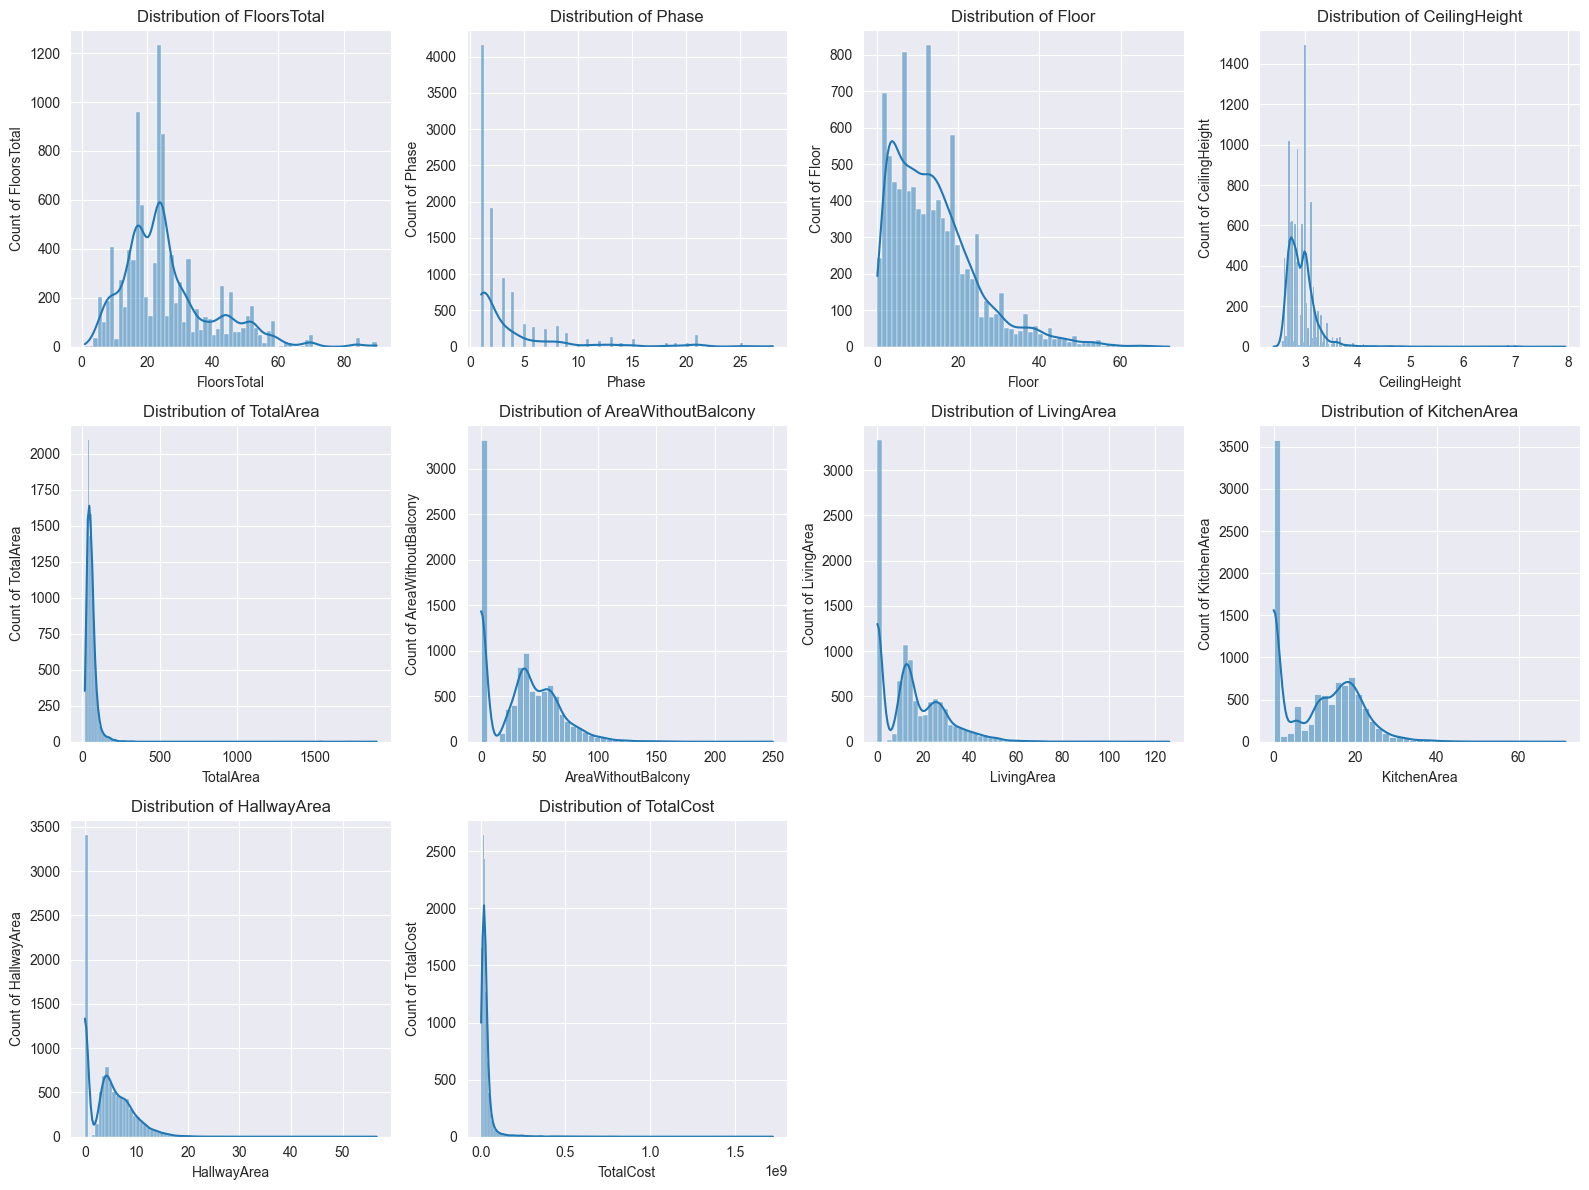

,Feature,overall_count,overall_mean,overall_std,overall_min,overall_25%,overall_50%,overall_75%,overall_max,overall_range,overall_IQR,overall_CV,overall_skewness,overall_kurtosis
0,FloorsTotal,57665.0,2.615836e+01,1.390597e+01,1.00,1.700000e+01,2.400000e+01,3.200000e+01,9.000000e+01,8.900000e+01,15.00,53.160685,1.230674,1.933158
1,Phase,57665.0,3.727512e+00,4.733560e+00,1.00,1.000000e+00,2.000000e+00,4.000000e+00,2.800000e+01,2.700000e+01,3.00,126.989776,2.655405,7.277964
2,Floor,57665.0,1.405868e+01,1.074834e+01,0.00,6.000000e+00,1.200000e+01,1.900000e+01,7.700000e+01,7.700000e+01,13.00,76.453395,1.335035,2.229312
3,CeilingHeight,57665.0,2.945899e+00,3.534602e-01,2.40,2.730000e+00,2.870000e+00,3.020000e+00,7.950000e+00,5.550000e+00,0.29,11.998381,5.422456,48.227411
4,TotalArea,57665.0,6.049492e+01,6.020041e+01,16.88,3.811000e+01,5.260000e+01,6.900000e+01,2.575600e+03,2.558720e+03,30.89,99.513179,20.286639,580.560902
5,AreaWithoutBalcony,57665.0,3.381885e+01,2.974366e+01,0.00,0.000000e+00,3.569000e+01,5.522000e+01,3.395000e+02,3.395000e+02,55.22,87.949959,0.599943,0.747618
6,LivingArea,57665.0,1.440473e+01,1.413935e+01,0.00,0.000000e+00,1.270000e+01,2.370000e+01,2.224000e+02,2.224000e+02,23.70,98.157674,1.375071,6.488368
7,KitchenArea,57665.0,1.049336e+01,9.643227e+00,0.00,0.000000e+00,1.120000e+01,1.820000e+01,8.110000e+01,8.110000e+01,18.20,91.898344,0.464099,-0.188784
8,HallwayArea,57665.0,4.430283e+00,4.249690e+00,0.00,0.000000e+00,4.100000e+00,7.200000e+00,5.662000e+01,5.662000e+01,7.20,95.923674,1.033193,3.052045
9,TotalCost,57665.0,3.638635e+07,8.480241e+07,2853540.00,1.425145e+07,2.220938e+07,3.356872e+07,4.408750e+09,4.405896e+09,19317270.00,233.061025,15.932094,428.889852


In [6]:
eda_sample = df.sample(n=min(10_000, len(df)), random_state=42)

plot_dynamic_hisplots_kdeplots(
    eda_sample,
    numerical_features + [target],
    ncols=4,
    figsize=(16, 12),
)
display(describe_numerical_combined(df, numerical_features + [target]))

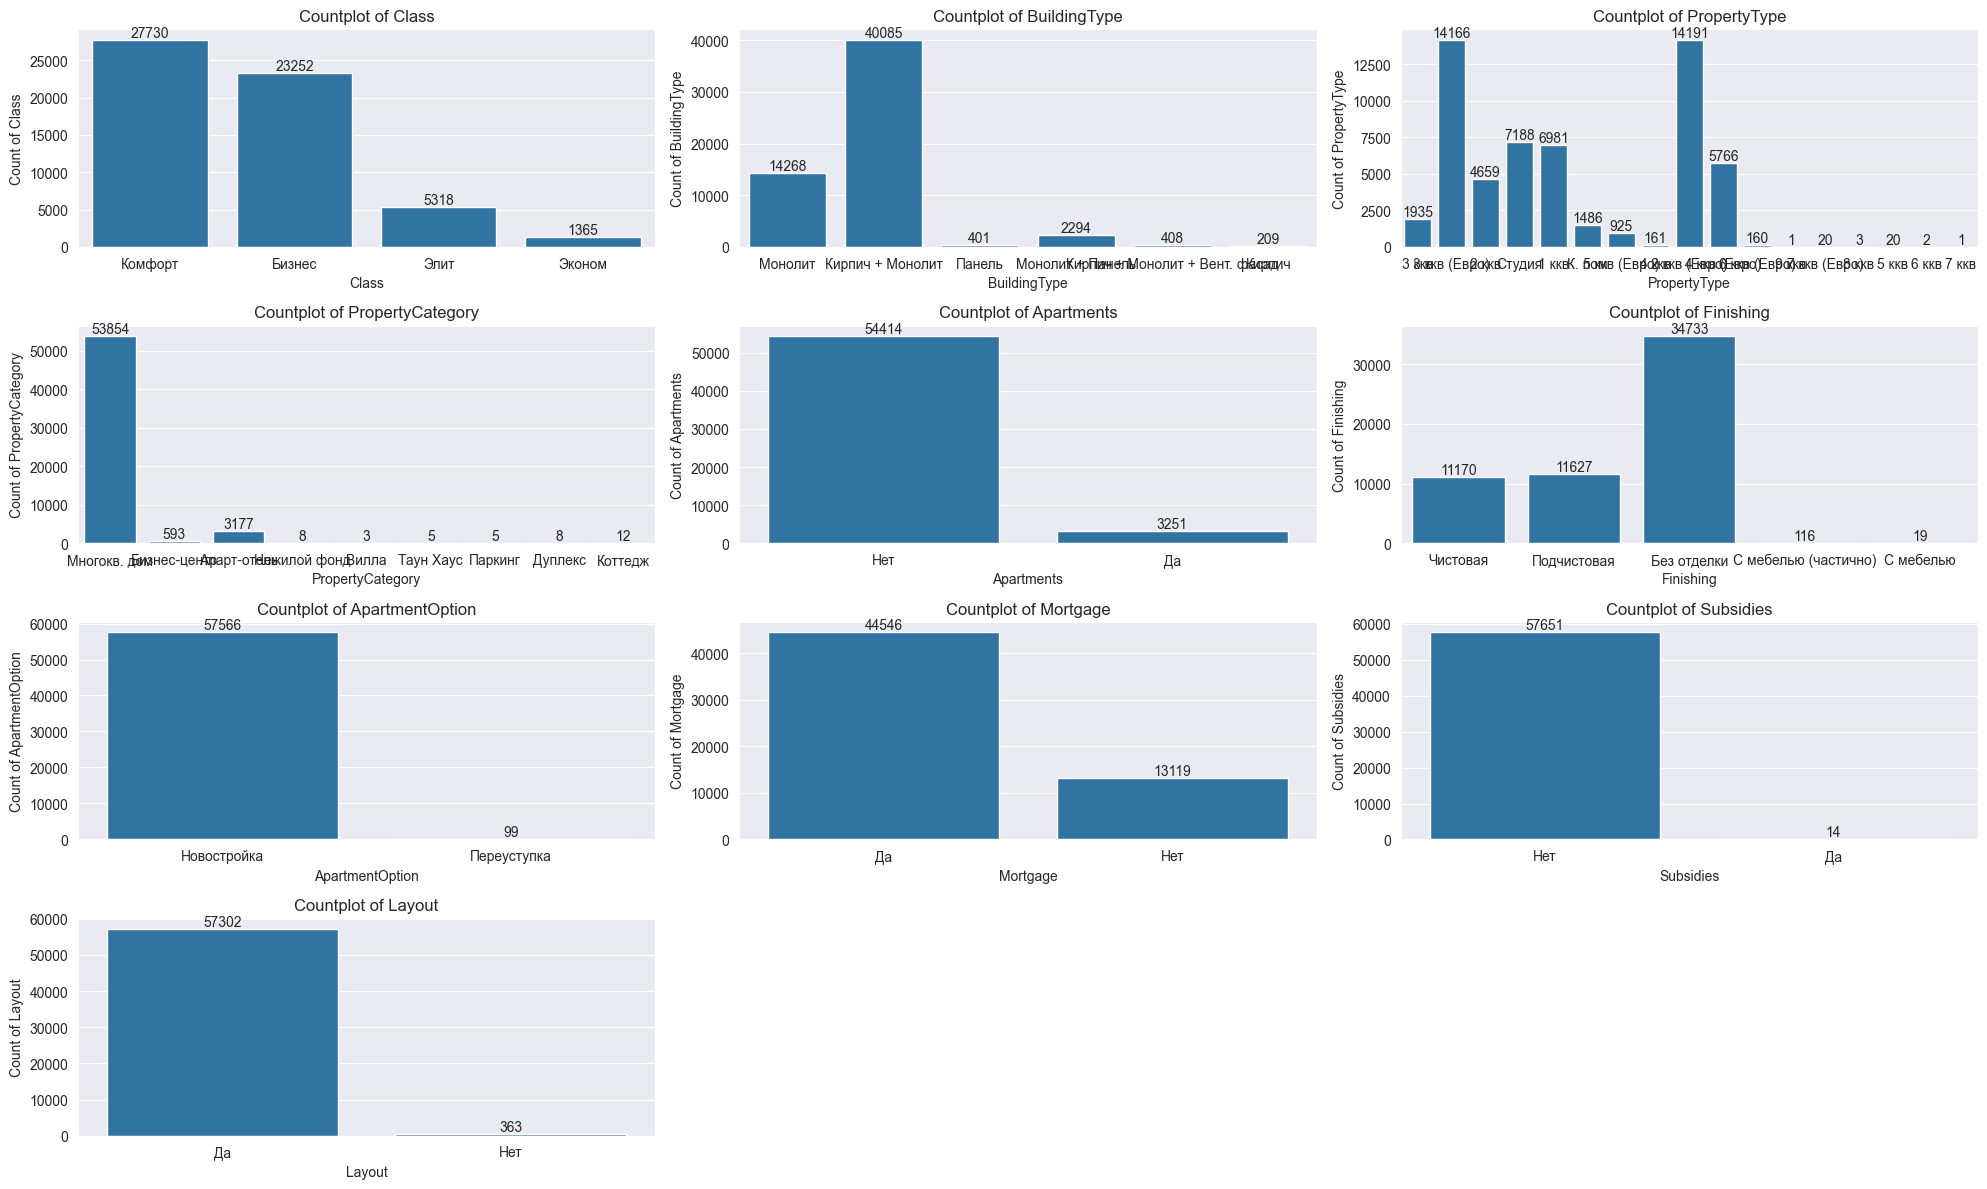

,Feature,overall_count,overall_unique,overall_top,overall_freq,overall_bottom,overall_freq_bottom,overall_top_percentage,overall_bottom_percentage,overall_n_categories
0,Class,57665,4,Комфорт,27730,Эконом,1365,48.09,2.37,4
1,BuildingType,57665,6,Кирпич + Монолит,40085,Кирпич,209,69.51,0.36,6
2,PropertyType,57665,17,2 ккв (Евро),14191,9 ккв,1,24.61,0.00,17
3,PropertyCategory,57665,9,Многокв. дом,53854,Вилла,3,93.39,0.01,9
4,Apartments,57665,2,Нет,54414,Да,3251,94.36,5.64,2
5,Finishing,57665,5,Без отделки,34733,С мебелью,19,60.23,0.03,5
6,ApartmentOption,57665,2,Новостройка,57566,Переуступка,99,99.83,0.17,2
7,Mortgage,57665,2,Да,44546,Нет,13119,77.25,22.75,2
8,Subsidies,57665,2,Нет,57651,Да,14,99.98,0.02,2
9,Layout,57665,2,Да,57302,Нет,363,99.37,0.63,2


In [7]:
plot_dynamic_countplot(
    df,
    categorical_features,
    ncols=3,
    figsize=(20, 12),
)
display(describe_categorical_combined(df, categorical_features))

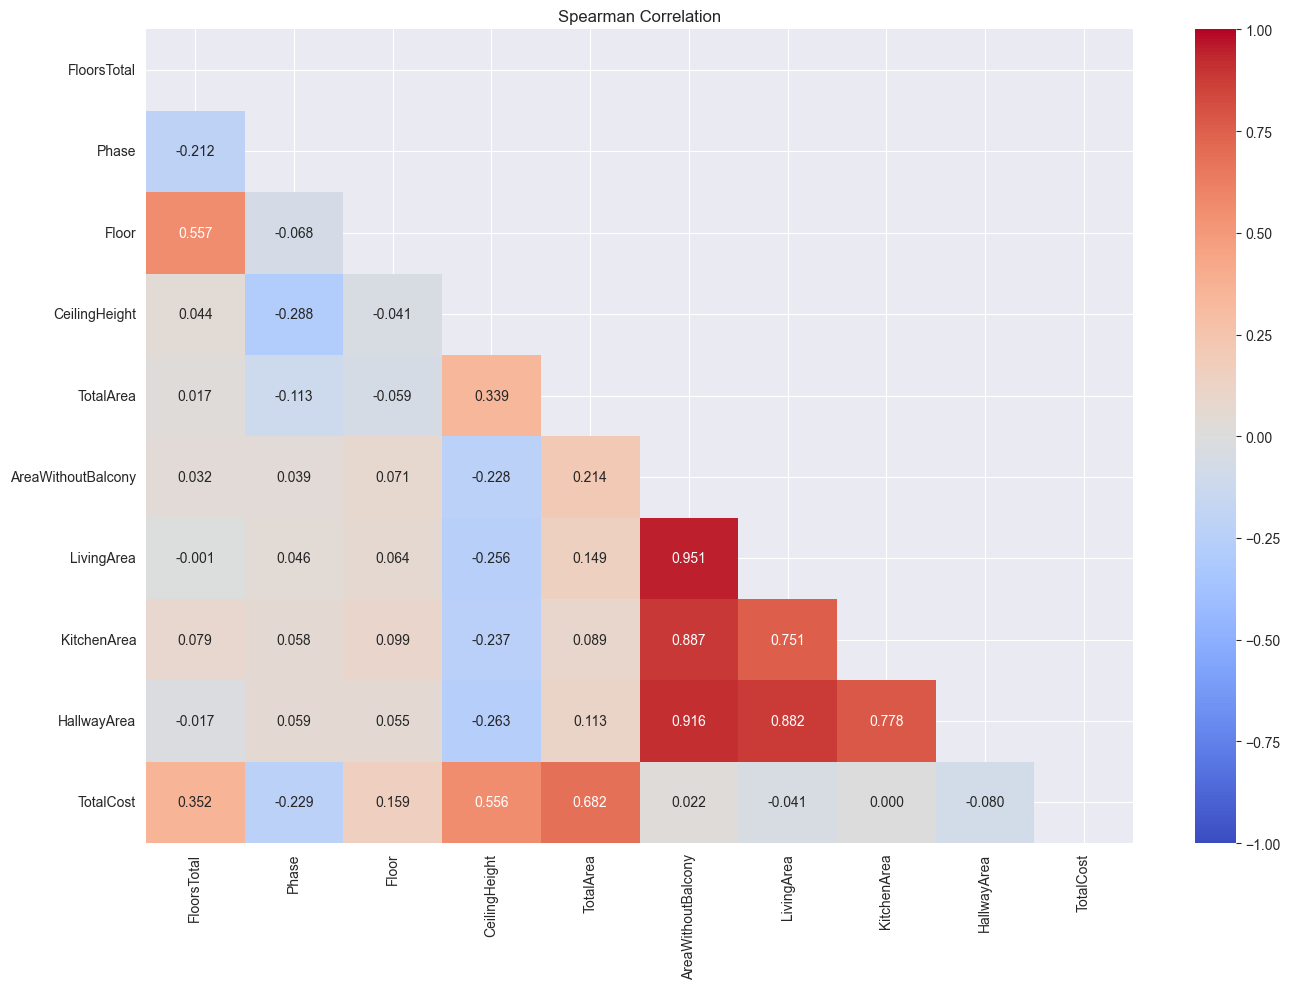

In [8]:
plot_correlation_heatmap(
    df,
    numerical_features + [target],
    corr_method="spearman",
    figsize=(14, 10),
)

### Geographical feature analysis
The raw data contains `District` and `Address`. `Address` is nearly unique, while `District` groups listings into a manageable number of market areas. The next cells compare their cardinality and show how median price varies by district.

District unique values: 113
Address unique values:  323


,listings
District,
МО Ленинский г.о.,3181
МО Мытищи г.о.,3126
Сосенское пос.,2983
Даниловский р-н,2884
МО Красногорский р-н,2210
МО Одинцовский г.о.,2168
Можайский р-н,2084
Хорошёвский р-н,1844
Московский пос.,1411


,count,median,mean
District,,,
Якиманка р-н,79,5.282400e+08,6.715635e+08
Хамовники р-н,169,5.055600e+08,6.121135e+08
Тверской р-н,176,4.348100e+08,5.191477e+08
Арбат р-н,48,4.313010e+08,4.626810e+08
Мещанский р-н,17,2.290924e+08,2.315152e+08
Фили-Давыдково р-н,49,1.519840e+08,1.718028e+08
Красносельский р-н,13,1.250200e+08,1.252203e+08
Пресненский р-н,1383,1.105954e+08,1.608509e+08
Академический р-н,18,1.027077e+08,1.178628e+08


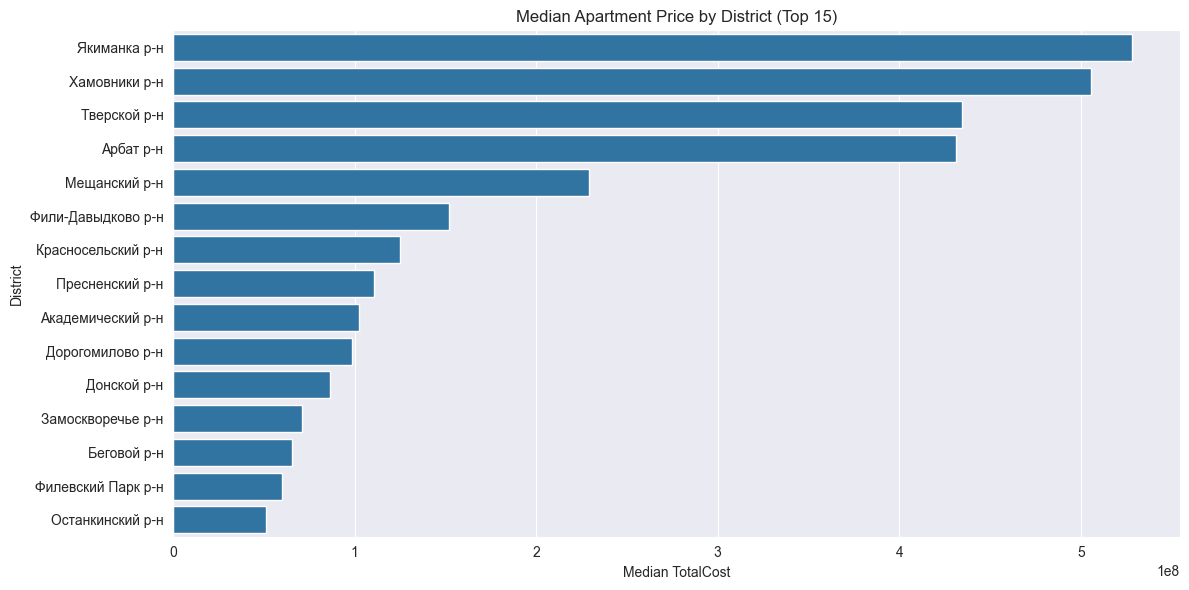

In [9]:
geo = df_raw[["District", "Address", target]].copy()
print(f"District unique values: {geo['District'].nunique():,}")
print(f"Address unique values:  {geo['Address'].nunique():,}")

district_counts = geo["District"].value_counts().head(15).to_frame("listings")
display(district_counts)

district_stats = (
    geo.groupby("District")[target]
       .agg(["count", "median", "mean"])
       .sort_values("median", ascending=False)
)
display(district_stats.head(15))

fig, ax = plt.subplots(figsize=(12, 6))
top_districts = district_stats.head(15)
sns.barplot(x=top_districts["median"].values, y=top_districts.index, ax=ax)
ax.set_title("Median Apartment Price by District (Top 15)")
ax.set_xlabel("Median TotalCost")
ax.set_ylabel("District")
plt.tight_layout()
plt.show()

### Geographical decision
`District` is retained and target-encoded with smoothing and cross-fitting. `Address` is dropped because it is too granular for a stable encoding and would create severe overfitting risk. Target encoding is fitted inside the training data only, then applied to validation and test.

## **STAGE 4: TRAIN / VALIDATION / TEST SPLIT**

The split is stratified by `Class` to keep the apartment segments represented in all three sets. All preprocessing is fitted after the split.

In [10]:
X_raw = df.drop(columns=[target])
y_raw = df[target]

X_train_raw, X_temp_raw, y_train_raw, y_temp_raw = train_test_split(
    X_raw, y_raw,
    test_size=0.25,
    random_state=42,
    stratify=X_raw["Class"],
)
X_val_raw, X_test_raw, y_val_raw, y_test_raw = train_test_split(
    X_temp_raw, y_temp_raw,
    test_size=0.2,
    random_state=42,
    stratify=X_temp_raw["Class"],
)

total = len(X_raw)
print(f"Total rows:   {total:,}")
print(f"Train:        {len(X_train_raw):,} ({len(X_train_raw)/total*100:.1f}%)")
print(f"Validation:   {len(X_val_raw):,} ({len(X_val_raw)/total*100:.1f}%)")
print(f"Test:         {len(X_test_raw):,} ({len(X_test_raw)/total*100:.1f}%)")

Total rows:   57,665
Train:        43,248 (75.0%)
Validation:   11,533 (20.0%)
Test:         2,884 (5.0%)


## **STAGE 5: PREPROCESSING FITTED ON TRAINING DATA**

### Missing-value imputation
The selected features have little or no missingness after basic cleaning, but the pipeline still checks and imputes using training statistics for robustness.

In [11]:
numeric_missing = [
    col for col in X_train_raw.columns
    if X_train_raw[col].isna().any() and pd.api.types.is_numeric_dtype(X_train_raw[col])
]
categorical_missing = [
    col for col in X_train_raw.columns
    if X_train_raw[col].isna().any() and col not in numeric_missing
]

train_medians = X_train_raw[numeric_missing].median()
train_modes = {}
for col in categorical_missing:
    mode = X_train_raw[col].mode()
    train_modes[col] = mode.iloc[0] if not mode.empty else "Unknown"

X_train_imp, _ = handle_missing_values(
    X_train_raw.copy(),
    columns=numeric_missing,
    strategy="median",
)
for col in categorical_missing:
    X_train_imp[col] = X_train_imp[col].fillna(train_modes[col])

def apply_training_imputation(X):
    X = X.copy()
    if numeric_missing:
        X[numeric_missing] = X[numeric_missing].fillna(train_medians)
    for col in categorical_missing:
        X[col] = X[col].fillna(train_modes[col])
    return X

X_val_imp = apply_training_imputation(X_val_raw)
X_test_imp = apply_training_imputation(X_test_raw)

print(f"Numeric columns imputed: {len(numeric_missing)}")
print(f"Categorical columns imputed: {len(categorical_missing)}")
print(f"Remaining train missing values: {X_train_imp.isna().sum().sum()}")

Numeric columns imputed: 0
Categorical columns imputed: 0
Remaining train missing values: 0


### Outlier handling
IQR limits are learned from the training features and target. Training rows outside the limits are removed. The same feature limits are applied to validation. The test set is kept untouched for the final estimate.

In [12]:
check_outliers_cols = numerical_features + [target]

outlier_summary = filter_outliers(
    pd.concat([X_train_imp, y_train_raw], axis=1),
    columns=check_outliers_cols,
    method="iqr",
    threshold=1.5,
    detect_only=True,
    verbose=False,
)
display(outlier_summary)

train_mask = filter_outliers(
    X_train_imp,
    columns=numerical_features,
    method="iqr",
    threshold=1.5,
    return_mask=True,
)[1]
X_train_clean = X_train_imp[train_mask].copy()
y_train_clean = y_train_raw[train_mask].copy()

def apply_training_limits(X, limits_df, columns):
    """Apply training-derived IQR limits to a validation/test feature frame."""
    mask = np.ones(len(X), dtype=bool)
    for _, row in limits_df.iterrows():
        col = row["Column Name"]
        if col in columns and col in X.columns:
            mask &= X[col].between(row["Lower Limit"], row["Upper Limit"]).to_numpy()
    return X[mask].copy(), mask

X_val_clean, val_mask = apply_training_limits(X_val_imp, outlier_summary, numerical_features)
y_val_clean = y_val_raw[val_mask].copy()

print(f"Train after outlier removal: {len(X_train_clean):,} rows")
print(f"Validation after limits:     {len(X_val_clean):,} rows")
print(f"Test kept untouched:         {len(X_test_imp):,} rows")

,Column Name,Outlier Exist,Lower Limit,Upper Limit,Outlier Data,Non-Outlier Data,Outlier Percentage (%)
0,FloorsTotal,True,-5.500000e+00,5.450000e+01,1950,41298,4.51
1,Phase,True,-3.500000e+00,8.500000e+00,4398,38850,10.17
2,Floor,True,-1.350000e+01,3.850000e+01,1701,41547,3.93
3,CeilingHeight,True,2.320000e+00,3.440000e+00,1717,41531,3.97
4,TotalArea,True,-8.550000e+00,1.158500e+02,2025,41223,4.68
5,AreaWithoutBalcony,True,-8.280000e+01,1.380000e+02,136,43112,0.31
6,LivingArea,True,-3.555000e+01,5.925000e+01,269,42979,0.62
7,KitchenArea,True,-2.730000e+01,4.550000e+01,79,43169,0.18
8,HallwayArea,True,-1.080000e+01,1.800000e+01,235,43013,0.54
9,TotalCost,True,-1.460407e+07,6.241684e+07,3527,39721,8.16


Train after outlier removal: 33,000 rows
Validation after limits:     8,805 rows
Test kept untouched:         2,884 rows


### Feature encoding
- `Class` and `Finishing` are ordinal.
- The remaining categorical features are one-hot encoded.
- `District` is mean/target encoded with built-in cross-fitting and smoothing.
- Encoders are fitted on training data and reused for validation and test.

**API note:** the current `feature_encoding` handles ordinal, one-hot, and mean encoding in one call and returns the fitted encoders. This replaces the older mix of manual mappings and separate encoder objects.

In [13]:
ordinal_cols = ["Class", "Finishing"]
ordinal_categories = {
    "Class": ["Эконом", "Комфорт", "Бизнес", "Элит"],
    "Finishing": [
        "Нет данных", "Без отделки", "Подчистовая",
        "Чистовая", "С мебелью (частично)", "С мебелью",
    ],
}
nominal_cols = [
    "BuildingType", "PropertyType", "PropertyCategory",
    "Apartments", "ApartmentOption", "Mortgage",
    "Subsidies", "Layout",
]
mean_encoding_cols = ["District"]

X_train_encoded, encoders = feature_encoding(
    data=X_train_clean.copy(),
    ordinal_columns=ordinal_cols,
    nominal_columns=nominal_cols,
    mean_encoding_columns=mean_encoding_cols,
    ordinal_categories=ordinal_categories,
    target=y_train_clean,
    mean_target_type="continuous",
    mean_smooth="auto",
    mean_cv=5,
    handle_unknown="ignore",
)
X_val_encoded, _ = feature_encoding(
    data=X_val_clean.copy(),
    ordinal_columns=ordinal_cols,
    nominal_columns=nominal_cols,
    mean_encoding_columns=mean_encoding_cols,
    ordinal_categories=ordinal_categories,
    encoders=encoders,
    handle_unknown="ignore",
)
X_test_encoded, _ = feature_encoding(
    data=X_test_imp.copy(),
    ordinal_columns=ordinal_cols,
    nominal_columns=nominal_cols,
    mean_encoding_columns=mean_encoding_cols,
    ordinal_categories=ordinal_categories,
    encoders=encoders,
    handle_unknown="ignore",
)

print(f"Encoded training shape: {X_train_encoded.shape}")
print(f"One-hot columns from PropertyType: {len([c for c in X_train_encoded.columns if c.startswith('PropertyType_')])}")
print(f"District encoded: {'District' in X_train_encoded.columns}")

Encoded training shape: (33000, 33)
One-hot columns from PropertyType: 9
District encoded: True


## **STAGE 6: FEATURE SELECTION**

Correlation and univariate importance are computed on training data only. The final feature set follows the case-study logic: total area, class, ceiling height, building scale, phase, finishing, target-encoded district, and property-type dummies.

In [14]:
df_train_encoded = pd.concat(
    [X_train_encoded.reset_index(drop=True), y_train_clean.reset_index(drop=True)],
    axis=1,
)
feature_feature_df, feature_target_df = calculate_correlation_tabular(
    df_train_encoded,
    target_col=target,
    method="spearman",
    corr_type="both",
)

Correlation Between Features:


,A,B,Corr Value,Corr Type
0,Apartments_Нет,PropertyCategory_Многокв. дом,0.951441,Positive
1,AreaWithoutBalcony,LivingArea,0.938936,Positive
2,BuildingType_Кирпич + Монолит,BuildingType_Монолит,0.921039,Negative
3,AreaWithoutBalcony,HallwayArea,0.906434,Positive
4,AreaWithoutBalcony,KitchenArea,0.878049,Positive
5,HallwayArea,LivingArea,0.863045,Positive
6,HallwayArea,KitchenArea,0.749243,Positive
7,KitchenArea,LivingArea,0.716788,Positive
8,Class,District,0.691543,Positive
9,PropertyCategory_Бизнес-центр,PropertyType_К. пом,0.677319,Positive



Correlation of Features to Target:


,Feature,Corr Value,Corr Type
0,District,0.838618,Positive
1,Class,0.642059,Positive
2,TotalArea,0.625565,Positive
3,CeilingHeight,0.493148,Positive
4,FloorsTotal,0.413541,Positive
5,PropertyType_Студия,0.354613,Negative
6,PropertyType_3 ккв (Евро),0.322133,Positive
7,PropertyType_4 ккв (Евро),0.299889,Positive
8,Floor,0.172559,Positive
9,AreaWithoutBalcony,0.114623,Positive


In [15]:
importance_f = calculate_feature_importance(
    X=X_train_encoded,
    y=y_train_clean.reset_index(drop=True),
    task="regression",
    method="f_regression",
    k="all",
)
importance_mi = calculate_feature_importance(
    X=X_train_encoded,
    y=y_train_clean.reset_index(drop=True),
    task="regression",
    method="mutual_info",
    k="all",
)

print("Top F-regression features")
display(importance_f.head(15).reset_index(drop=True))
print("Top mutual-information features")
display(importance_mi.head(15).reset_index(drop=True))

Top F-regression features


,Feature,Score,P_Values
0,District,68275.480883,0.000000e+00
1,TotalArea,14602.344198,0.000000e+00
2,Class,14373.772520,0.000000e+00
3,CeilingHeight,8368.994278,0.000000e+00
4,PropertyType_4 ккв (Евро),2358.322016,0.000000e+00
5,PropertyType_Студия,1732.524967,0.000000e+00
6,PropertyType_3 ккв (Евро),1419.872449,2.899405e-304
7,FloorsTotal,1171.922683,2.039936e-252
8,Phase,336.546050,8.500556e-75
9,Mortgage_Нет,318.928371,5.357298e-71


Top mutual-information features


,Feature,Score,P_Values
0,TotalArea,1.111118,None
1,AreaWithoutBalcony,0.886781,None
2,District,0.877833,None
3,LivingArea,0.787276,None
4,KitchenArea,0.764139,None
5,HallwayArea,0.633466,None
6,CeilingHeight,0.569765,None
7,FloorsTotal,0.565501,None
8,Class,0.363754,None
9,Phase,0.168701,None


In [16]:
base_cols = [
    "TotalArea", "Class", "CeilingHeight", "FloorsTotal",
    "Phase", "Finishing", "District",
]
property_type_cols = [
    col for col in X_train_encoded.columns if col.startswith("PropertyType_")
]
selected_cols = [col for col in base_cols + property_type_cols if col in X_train_encoded.columns]

X_train_selected = X_train_encoded[selected_cols].copy()
X_val_selected = X_val_encoded[selected_cols].copy()
X_test_selected = X_test_encoded[selected_cols].copy()

print(f"Selected {len(selected_cols)} features")
print(selected_cols)
print(f"Train shape: {X_train_selected.shape}")
print(f"Validation shape: {X_val_selected.shape}")
print(f"Test shape: {X_test_selected.shape}")

Selected 16 features
['TotalArea', 'Class', 'CeilingHeight', 'FloorsTotal', 'Phase', 'Finishing', 'District', 'PropertyType_2 ккв', 'PropertyType_2 ккв (Евро)', 'PropertyType_3 ккв', 'PropertyType_3 ккв (Евро)', 'PropertyType_4 ккв', 'PropertyType_4 ккв (Евро)', 'PropertyType_5 ккв (Евро)', 'PropertyType_К. пом', 'PropertyType_Студия']
Train shape: (33000, 16)
Validation shape: (8805, 16)
Test shape: (2884, 16)


### Feature scaling
`Class`, `Phase`, and `Finishing` use min-max scaling because they are bounded ordinal codes. `TotalArea`, `CeilingHeight`, `FloorsTotal`, and `District` use standardization. Property-type dummies remain 0/1.

In [17]:
scaling_config = {
    "minmax": {
        "columns": ["Class", "Phase", "Finishing"],
    },
    "standard": {
        "columns": ["TotalArea", "CeilingHeight", "FloorsTotal", "District"],
    },
}

X_train_scaled, scalers = feature_scaling(
    X_train_selected,
    scaling_config=scaling_config,
)
X_val_scaled, _ = feature_scaling(
    X_val_selected,
    scaling_config=scaling_config,
    scaler=scalers,
)
X_test_scaled, _ = feature_scaling(
    X_test_selected,
    scaling_config=scaling_config,
    scaler=scalers,
)

print(f"Train scaled shape: {X_train_scaled.shape}")
print(f"Scaler keys: {list(scalers.keys())}")

Train scaled shape: (33000, 16)
Scaler keys: ['minmax', 'standard']


## **STAGE 7: BASELINE REGRESSION MODELS**

Seven baseline regressors are trained on the scaled training set and evaluated on the validation set. Cross-validated metrics use 3-fold CV with one repeat to keep the runtime reasonable on this larger dataset.

In [18]:
model_keys = [
    "linearregression", "ridge", "lasso", "knn",
    "decisiontree", "randomforest", "xgboost",
]
display_names = {
    "linearregression": "Linear Regression",
    "ridge": "Ridge",
    "lasso": "Lasso",
    "knn": "K-Nearest Neighbors",
    "decisiontree": "Decision Tree",
    "randomforest": "Random Forest",
    "xgboost": "XGBoost",
}

baseline_models = {
    display_names[key]: get_model_pipeline(key, random_state=42)
    for key in model_keys
}

for name, model in baseline_models.items():
    model.fit(X_train_scaled, y_train_clean)
    print(f"Trained {name}")

Trained Linear Regression
Trained Ridge
Trained Lasso
Trained K-Nearest Neighbors
Trained Decision Tree
Trained Random Forest
Trained XGBoost


In [19]:
baseline_metrics = {}
for name, model in baseline_models.items():
    baseline_metrics[name] = eval_regression(
        model=model,
        X_train=X_train_scaled,
        y_train=y_train_clean,
        X_test=X_val_scaled,
        y_test=y_val_clean,
        plot_predicted_vs_actual=False,
        plot_residuals=False,
        plot_residuals_dist=False,
        n_splits=3,
        n_repeats=1,
        display=False,
        show_plots=False,
    )
    print(f"Evaluated {name}")

Evaluated Linear Regression
Evaluated Ridge
Evaluated Lasso
Evaluated K-Nearest Neighbors
Evaluated Decision Tree
Evaluated Random Forest
Evaluated XGBoost


In [20]:
comparison = compare_cv_metrics_regression(baseline_metrics, as_numeric=True)
comparison = comparison.sort_values("R2", ascending=False).reset_index(drop=True)
display(comparison)

,Model,MAE,MSE,RMSE,MAPE,R2
0,XGBoost,1.693324e+06,1.755836e+13,4.184911e+06,0.060110,0.961380
1,Random Forest,1.399887e+06,1.767485e+13,4.198422e+06,0.042858,0.961110
2,Decision Tree,1.608615e+06,2.751457e+13,5.239580e+06,0.048809,0.939518
3,K-Nearest Neighbors,1.858290e+06,3.258945e+13,5.706876e+06,0.057737,0.928223
4,Ridge,5.153509e+06,8.844326e+13,9.402898e+06,0.227238,0.805042
5,Lasso,5.155069e+06,8.844323e+13,9.402899e+06,0.227375,0.805042
6,Linear Regression,5.155073e+06,8.844323e+13,9.402899e+06,0.227376,0.805042


In [21]:
best_model_name = comparison.iloc[0]["Model"]
best_model_key = {name: key for key, name in display_names.items()}[best_model_name]
top_two = comparison.head(2)["Model"].tolist()
tuning_key = "randomforest" if "Random Forest" in top_two else best_model_key

print(f"Best baseline by cross-validated R²: {best_model_name}")
print(f"Top two models: {top_two}")
print(f"Model selected for tuning: {tuning_key}")

Best baseline by cross-validated R²: XGBoost
Top two models: ['XGBoost', 'Random Forest']
Model selected for tuning: randomforest


## **STAGE 8: HYPERPARAMETER TUNING**

The selected model is tuned with randomized search on the training set. The validation set is used only to report the holdout score.

In [22]:
tuned_search, fit_time = tune_single_model_regression(
    model_name=tuning_key,
    X_train=X_train_scaled,
    y_train=y_train_clean,
    X_test=X_val_scaled,
    y_test=y_val_clean,
    scoring="r2",
    search_method="random",
    n_iter=6,
    n_splits=3,
    n_repeats=1,
    random_state=42,
    display=False,
    plot_validation_curves=False,
    plot_learning_curves=False,
    progress_bar=False,
    show=False,
)

print(f"Tuning time: {fit_time:.2f} seconds")
print(f"Best CV R²: {tuned_search.best_score_:.4f}")
print(f"Best parameters: {tuned_search.best_params_}")

Tuning time: 501.74 seconds
Best CV R²: 0.9488
Best parameters: {'rf__n_estimators': 50, 'rf__min_samples_split': 7, 'rf__min_samples_leaf': 2, 'rf__max_features': 'log2', 'rf__max_depth': 20, 'rf__criterion': 'absolute_error'}


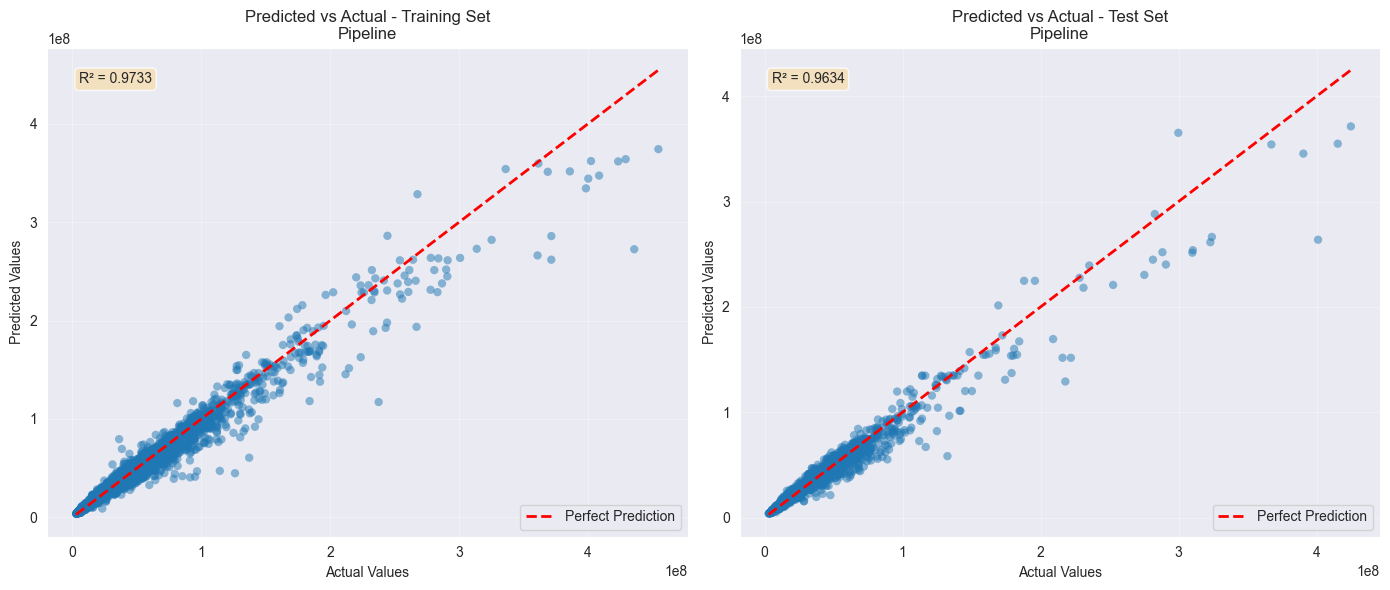

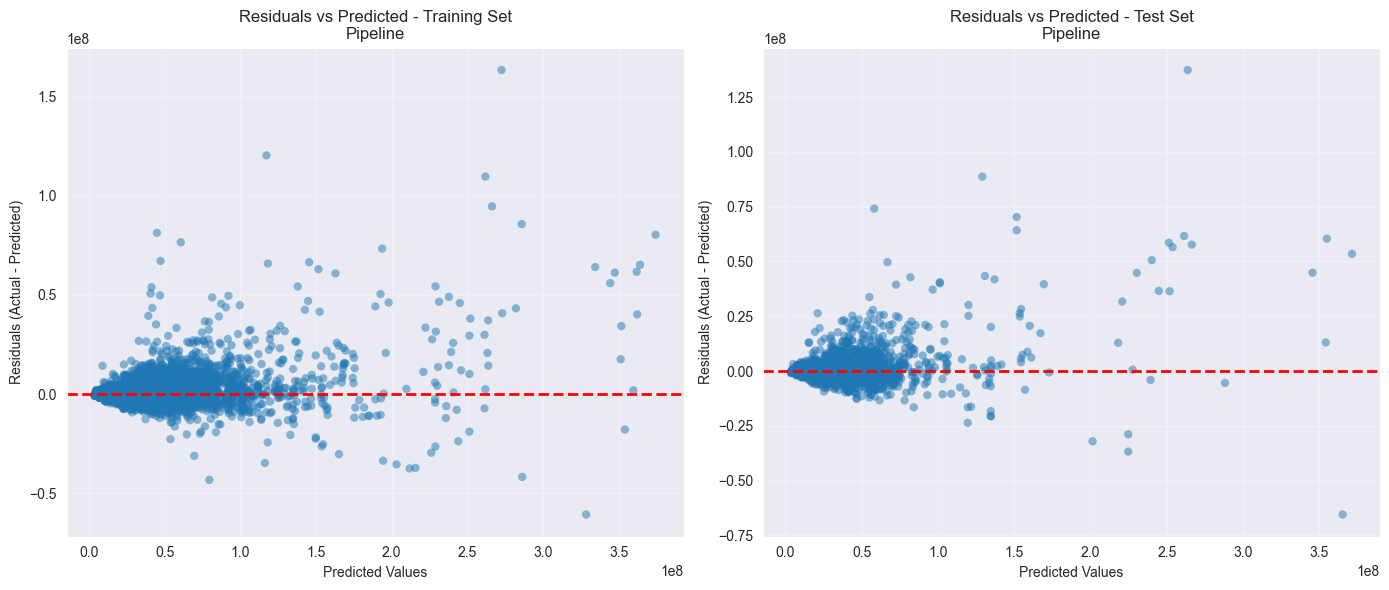

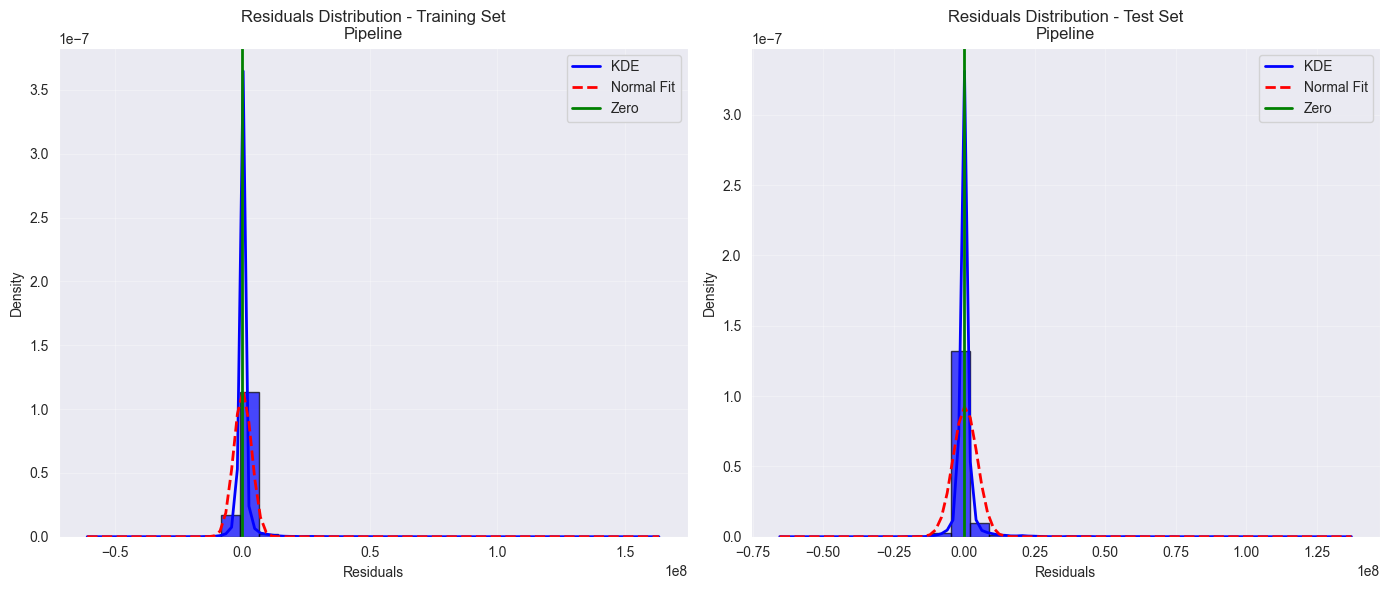

In [23]:
tuned_model = tuned_search.best_estimator_

tuned_metrics = eval_regression(
    model=tuned_model,
    X_train=X_train_scaled,
    y_train=y_train_clean,
    X_test=X_val_scaled,
    y_test=y_val_clean,
    plot_predicted_vs_actual=True,
    plot_residuals=True,
    plot_residuals_dist=True,
    n_splits=3,
    n_repeats=1,
    display=False,
)

## **STAGE 9: MODEL INTERPRETABILITY**

Two complementary views are used:
1. **Impurity-based importance** from the fitted tree ensemble.
2. **Permutation importance** on the validation set, which measures the R² drop when a feature is shuffled.

Permutation importance is computed on validation data to reflect out-of-sample reliance rather than training memorization.

In [24]:
final_estimator = tuned_model[-1]

if hasattr(final_estimator, "feature_importances_"):
    gini_importance = pd.DataFrame({
        "Feature": X_train_scaled.columns,
        "Importance": final_estimator.feature_importances_,
    }).sort_values("Importance", ascending=False)
    display(gini_importance.head(15).reset_index(drop=True))
else:
    gini_importance = None
    print("The selected model does not expose feature_importances_.")

,Feature,Importance
0,District,0.329518
1,TotalArea,0.222528
2,Class,0.126673
3,FloorsTotal,0.089160
4,CeilingHeight,0.088896
5,Phase,0.029448
6,PropertyType_4 ккв (Евро),0.024236
7,Finishing,0.022525
8,PropertyType_Студия,0.022146
9,PropertyType_3 ккв (Евро),0.019946


In [25]:
perm_result = permutation_importance(
    tuned_model,
    X_val_scaled,
    y_val_clean,
    n_repeats=5,
    random_state=42,
    scoring="r2",
    n_jobs=-1,
)

permutation_importance_df = pd.DataFrame({
    "Feature": X_val_scaled.columns,
    "Importance_Mean": perm_result.importances_mean,
    "Importance_Std": perm_result.importances_std,
}).sort_values("Importance_Mean", ascending=False)

display(permutation_importance_df.head(15).reset_index(drop=True))

,Feature,Importance_Mean,Importance_Std
0,District,0.540042,0.003628
1,TotalArea,0.317750,0.002752
2,Class,0.199802,0.007145
3,CeilingHeight,0.083572,0.006014
4,FloorsTotal,0.076539,0.002993
5,Phase,0.017881,0.001072
6,Finishing,0.017636,0.002319
7,PropertyType_2 ккв (Евро),0.013192,0.001075
8,PropertyType_3 ккв (Евро),0.010742,0.002493
9,PropertyType_4 ккв (Евро),0.008834,0.000945


In [26]:
if gini_importance is not None:
    n_top = min(15, len(gini_importance), len(permutation_importance_df))
    importance_comparison = pd.DataFrame({
        "Rank": range(1, n_top + 1),
        "Gini Feature": gini_importance.head(n_top)["Feature"].values,
        "Gini Importance": gini_importance.head(n_top)["Importance"].values,
        "Permutation Feature": permutation_importance_df.head(n_top)["Feature"].values,
        "Permutation Importance": permutation_importance_df.head(n_top)["Importance_Mean"].values,
    })
    display(importance_comparison)
else:
    print("Gini importance is unavailable for this model; see permutation importance above.")

,Rank,Gini Feature,Gini Importance,Permutation Feature,Permutation Importance
0,1,District,0.329518,District,0.540042
1,2,TotalArea,0.222528,TotalArea,0.317750
2,3,Class,0.126673,Class,0.199802
3,4,FloorsTotal,0.089160,CeilingHeight,0.083572
4,5,CeilingHeight,0.088896,FloorsTotal,0.076539
5,6,Phase,0.029448,Phase,0.017881
6,7,PropertyType_4 ккв (Евро),0.024236,Finishing,0.017636
7,8,Finishing,0.022525,PropertyType_2 ккв (Евро),0.013192
8,9,PropertyType_Студия,0.022146,PropertyType_3 ккв (Евро),0.010742
9,10,PropertyType_3 ккв (Евро),0.019946,PropertyType_4 ккв (Евро),0.008834


### Interpretability notes
- Features that rank highly in both methods are the most trustworthy drivers.
- Gini importance can favor high-cardinality or frequently split features.
- Permutation importance can understate correlated features because shuffling one feature leaves its correlated partner intact.
- `TotalArea`, `District`, `Class`, and `Finishing` are expected to dominate. If a property-type dummy ranks unexpectedly high, check for small-group effects.

## **STAGE 10: FINAL TEST-SET EVALUATION**

The test set has not been used for imputation, outlier limits, encoding, feature selection, scaling, or tuning. This is the final unbiased estimate.

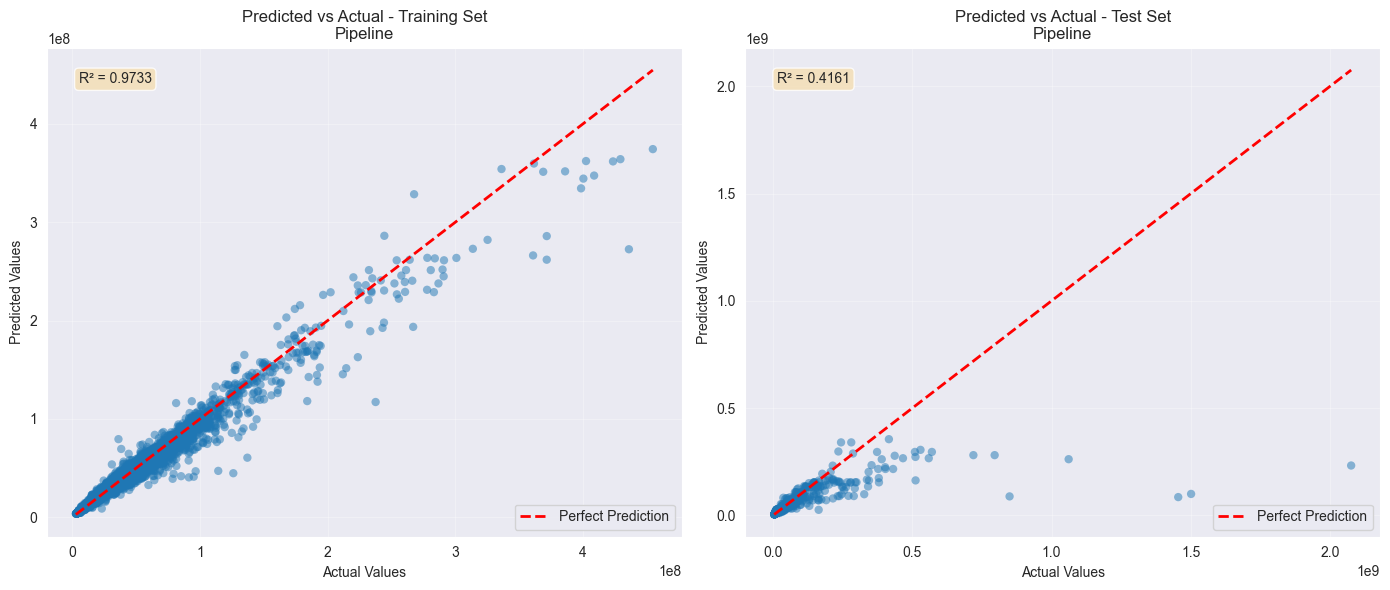

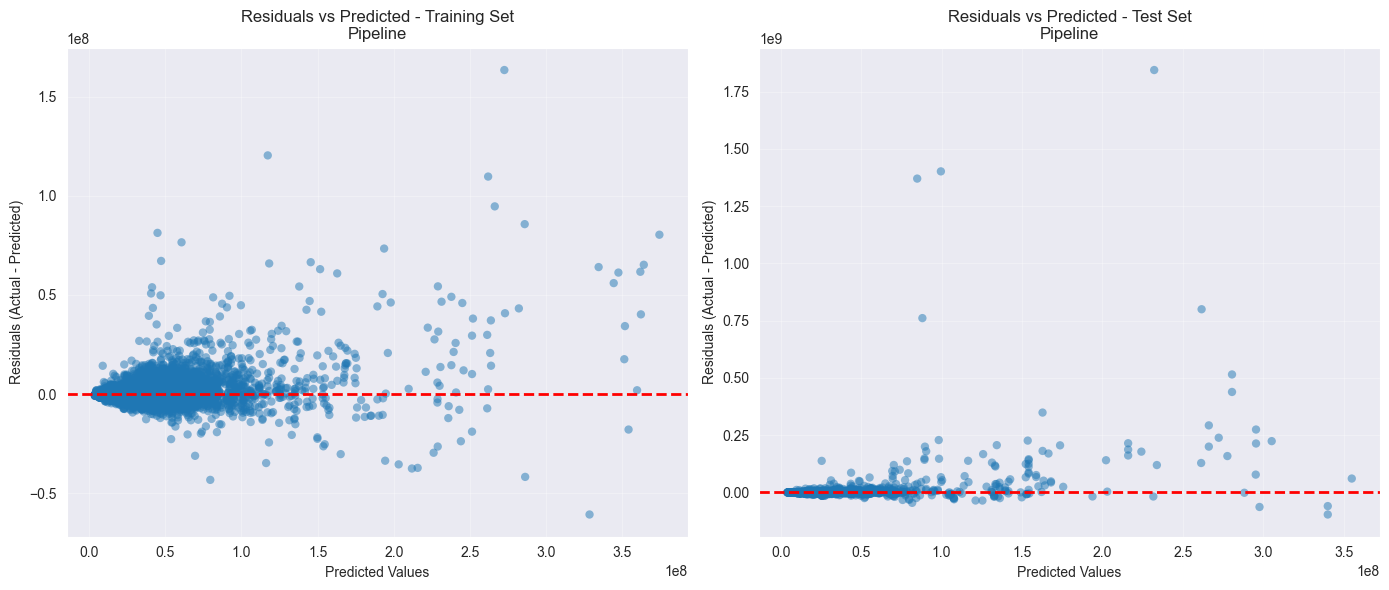

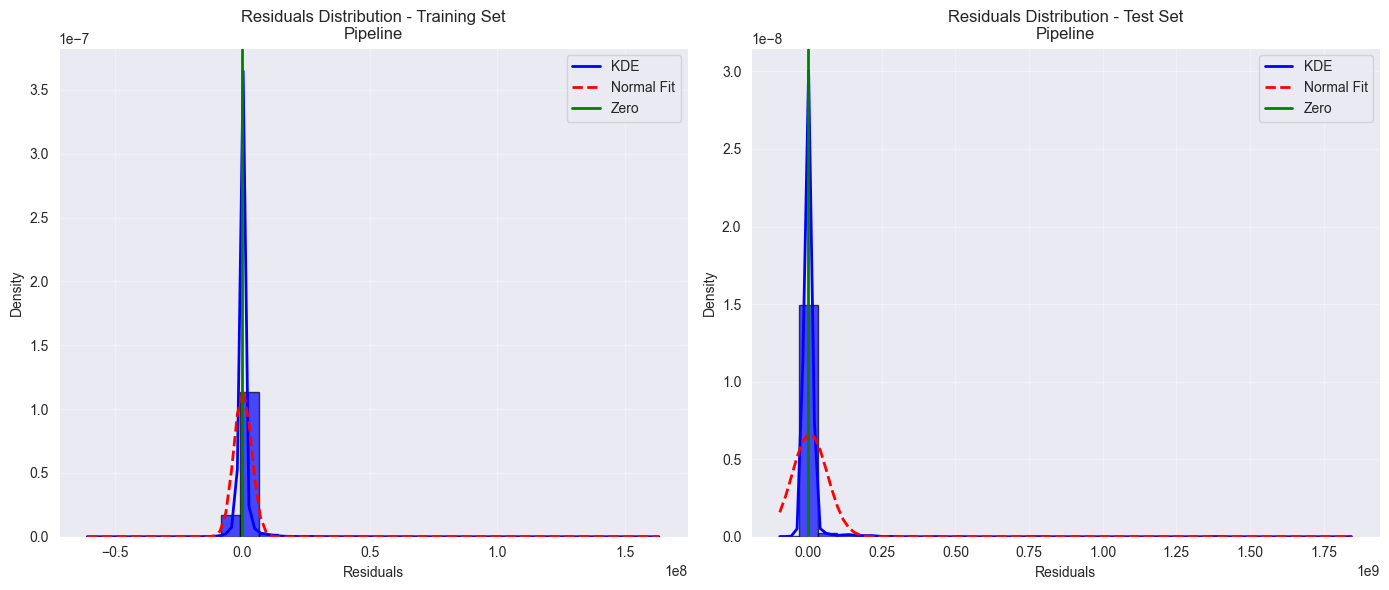

,Metric,Test
0,MAE,7.826304e+06
1,RMSE,6.020524e+07
2,MAPE (%),8.706185e+00
3,R²,4.160576e-01


Average test price: 36,299,958
MAE as % of average price: 21.56%
RMSE as % of average price: 165.85%


In [27]:
metrics_test = eval_regression(
    model=tuned_model,
    X_train=X_train_scaled,
    y_train=y_train_clean,
    X_test=X_test_scaled,
    y_test=y_test_raw,
    plot_predicted_vs_actual=True,
    plot_residuals=True,
    plot_residuals_dist=True,
    n_splits=3,
    n_repeats=1,
    display=False,
)

test_summary = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "MAPE (%)", "R²"],
    "Test": [
        metrics_test["mae"]["test"],
        metrics_test["rmse"]["test"],
        metrics_test["mape"]["test"] * 100,
        metrics_test["r2"]["test"],
    ],
})
display(test_summary)

print(f"Average test price: {y_test_raw.mean():,.0f}")
print(f"MAE as % of average price: {metrics_test['mae']['test']/y_test_raw.mean()*100:.2f}%")
print(f"RMSE as % of average price: {metrics_test['rmse']['test']/y_test_raw.mean()*100:.2f}%")

## **STAGE 11: SAVE MODEL AND PREPROCESSING ARTIFACTS**

The artifacts are saved under `models/new_regression_2/`. They include the fitted model, selected feature order, scalers, encoders, scaling statistics, categorical values, and metadata. The notebook does not save the test set.

In [ ]:
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(tuned_model, ARTIFACT_DIR / "final_model.joblib")
joblib.dump(selected_cols, ARTIFACT_DIR / "feature_names.joblib")
joblib.dump(scalers, ARTIFACT_DIR / "scalers.joblib")
joblib.dump(encoders, ARTIFACT_DIR / "encoders.joblib")

scaling_stats = {}
for method, config in scaling_config.items():
    scaling_stats[method] = {}
    for col in config["columns"]:
        if method == "minmax":
            scaling_stats[method][col] = {
                "min": float(X_train_selected[col].min()),
                "max": float(X_train_selected[col].max()),
            }
        elif method == "standard":
            scaling_stats[method][col] = {
                "mean": float(X_train_selected[col].mean()),
                "std": float(X_train_selected[col].std()),
            }
joblib.dump(scaling_stats, ARTIFACT_DIR / "scaling_stats.joblib")

categorical_values = {
    col: sorted(X_train_raw[col].dropna().astype(str).unique().tolist())
    for col in categorical_features + ["District"]
}
joblib.dump(categorical_values, ARTIFACT_DIR / "categorical_values.joblib")

metadata = {
    "target": target,
    "numerical_features": numerical_features,
    "categorical_features": categorical_features,
    "selected_features": selected_cols,
    "model_key": tuning_key,
    "best_params": tuned_search.best_params_,
    "validation_metrics": {key: value for key, value in tuned_metrics.items() if key != "cv"},
    "test_metrics": {key: value for key, value in metrics_test.items() if key != "cv"},
}
joblib.dump(metadata, ARTIFACT_DIR / "metadata.joblib")

print("Saved artifacts:")
for path in sorted(ARTIFACT_DIR.glob("*.joblib")):
    print(f"  {path.name}: {path.stat().st_size / 1024:.1f} KB")

## **STAGE 12: CONCLUSION AND NEXT STEPS**

### What the workflow shows
- Geographical information is valuable, but `District` must be target-encoded carefully to avoid leakage.
- Tree-based models capture non-linear size and location effects better than a plain linear baseline.
- Outlier removal and feature selection improve stability but change the population being modeled.
- Permutation importance on validation data is a useful sanity check on the model's reasoning.

### Practical recommendations
1. Review the largest residuals manually; unusual layouts, penthouses, and data-entry errors often dominate the error tail.
2. Keep the saved encoders and scalers with the model; inference must reproduce the exact training transformations.
3. Monitor `District`, `Class`, and `TotalArea` drift after deployment.
4. Add features that are missing from this extract, such as transport access, school quality, and floor-plan quality.
5. Re-tune periodically as the market changes; the current model is a baseline, not a fixed pricing rule.

### Limitations
- The dataset is a single extract and may not represent the current market.
- Target encoding of `District` is powerful but can overfit rare districts; smoothing and cross-fitting reduce, but do not eliminate, this risk.
- Outlier removal excludes extreme luxury units from the training population.
- The model predicts association, not causal price effects.